<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/19_Cybersecurity_Anomaly_Detection/QRBM_AnomalyDetection_Moro2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum restricted Boltzmann machine for anomaly detection: Moro and Prati (2023) step by step

This notebook re-implements, runs and checks the method of

> Lorenzo Moro and Enrico Prati, "Anomaly detection speed-up by quantum restricted Boltzmann machines",
> *Communications Physics* 6, 269 (2023). DOI 10.1038/s42005-023-01390-y

The paper trains a restricted Boltzmann machine (RBM) as a binary network-intrusion detector on NSL-KDD and
CSE-CIC-IDS2018. The *classical* RBM estimates the "negative phase" of the gradient with k steps of Gibbs sampling
(contrastive divergence, CD-k); the *quantum* RBM (QRBM) replaces those Gibbs steps by samples drawn from a D-Wave
Advantage 4.1 annealer, which returns states approximately distributed according to the Boltzmann distribution of
the RBM energy. The paper's headline result is a timing comparison (Table 3): the annealer evaluates the negative phase
up to 64x faster than a single CPU core. Code and data are "available upon reasonable request", so everything here is
written from the paper's text.

**What the notebook does.** It downloads NSL-KDD (the paper's first dataset), binarises the 41 features the way the
Methods section describes (one-hot / binary codes for nominal features, histogram bins for real-valued ones, the label
written three times into the last three visible units), trains the classical RBM with CD-k for the paper's k values
(1, 10, 100, 1000), classifies by *reconstructing the label bits* with a majority vote, and redraws Fig. 5 and Table 1.
The D-Wave annealer is not available here, so the QRBM is run with a **stand-in sampler**: D-Wave's own
`dimod` / `dwave-samplers` simulated-annealing sampler draws the paper's 10 samples per update from the very same
binary quadratic model (the RBM energy at effective temperature 1) that the paper embeds on the QPU. On a toy RBM the
stand-in is checked against the exact Boltzmann distribution. Random forest, RBF-SVM and logistic regression are trained
on the identical bits, the negative-phase times of CD-k and of the stand-in are measured for the paper's model size,
and the last section puts the paper's Tables 1-3 next to our numbers with a verdict per claim. The QPU timing itself
cannot be checked without hardware and is marked as such.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and *Runtime -> Run all*. The first cell installs
the pinned `dimod` and `dwave-samplers`; no D-Wave account, no GPU and no quantum-cloud token are needed.

**Runtime.** With `FAST_MODE = True` (1,000 updates, CD-1 and CD-10, 2 seeds) the notebook took about 3 minutes on the
validation machine, a shared 8-core laptop CPU; expect about 5 minutes on a Colab CPU. With `FAST_MODE = False` (the paper's 2,000 updates, CD-1/10/100/1000,
3 seeds, exploitation up to 1,000 Gibbs steps) it took 57 minutes; 43 of them are CD-1000 training and the k = 1000 read-out. The committed
notebook contains the outputs of the run named in the configuration cell.

**What you get at the end.** Accuracy, F1 and the normalised TP/FP/FN/TN of the paper for the classical RBM at every
training and exploitation k, the same for the stand-in QRBM, learning curves ("epochs to reach a target accuracy"),
the measured negative-phase times for the paper's model size, confusion matrices, the paper's Fig. 5 redrawn from your
own run, and a table with one verdict per number the paper reports for NSL-KDD.


## The paper in one page

**Problem.** Network intrusion detection as binary anomaly detection: decide whether a connection record is benign or
an attack. Two datasets: NSL-KDD (125,972 training / 22,543 test records, 41 raw features) and CSE-CIC-IDS2018
(3,040,074 records after cleaning, 80+ features). This notebook runs NSL-KDD only; CSE-CIC-IDS2018 is a multi-gigabyte
AWS/Kaggle download and the paper's own feature-clustering step is only partly specified.

**Decision.** An RBM used as a classifier (Methods, "Feature extraction"): every record is binarised, the label is
appended **three times** (attack = 000, benign = 111) as the last visible units; after training, the feature bits are
loaded into the visible layer, the model reconstructs the three label bits and a majority vote decides the class.

**Model (Eq. 1-6).** Energy $E(v,h) = -\sum_i a_i v_i - \sum_j b_j h_j - \sum_{ij} v_i W_{ij} h_j$, Boltzmann
distribution $P(v,h) \propto e^{-E}$, conditionals $P(h_j=1|v) = \sigma(b_j + \sum_i v_i W_{ij})$ and
$P(v_i=1|h) = \sigma(a_i + \sum_j W_{ij} h_j)$. Gradient ascent on the log-likelihood with learning rate $\epsilon$;
positive phase from the data, negative phase from model samples. 30 hidden units for NSL-KDD (chosen by increasing
until no further improvement), 90 for CSE-CIC-IDS2018; 2,000 training epochs; metrics averaged over 10 runs.

**Classical RBM.** CD-k: start a Gibbs chain at a data vector, run k steps, use $(v^{(k)}, h^{(k)})$ for the negative
phase. The paper varies k = 1, 10, 100, 1000 during training (Fig. 5: for NSL-KDD the training k makes no difference)
and during exploitation (Table 1: accuracy 0.906 -> 0.938 from k = 1 to k = 1000 on NSL-KDD).

**Quantum RBM.** The weights and biases are embedded on the D-Wave Advantage 4.1 (minorminer, chains of qubits);
one anneal returns one $(v, h)$ sample distributed as $e^{-E/T_{eff}}$ (Eq. 7); the energies are rescaled by a factor
$\alpha$ so that $T_{eff} = 1$. **Ten samples per update** are enough to train. Table 2: NSL-KDD accuracy
0.937 +- 0.001, F1 0.935 +- 0.001, comparable to the classical RBM.

**Timing (Fig. 2-4, Table 3).** QPU access time per update is ~0.016 s for 10 samples and grows as 0.514 us per unit
per sample; the classical negative phase with k = 10 for the NSL-KDD model takes 0.070 s on one Threadripper core
(0.035 s on 128 threads), hence a 4x (2x) speed-up on NSL-KDD and 64x (41x) on CSE-CIC-IDS2018 where k = 100 is
needed.

**Claims checked here (NSL-KDD).**

| Source | Claim |
|---|---|
| Table 1 | RBM, exploitation k = 1 / 10 / 100 / 1000: accuracy 0.906 / 0.935 / 0.937 / 0.938, F1 0.901 / 0.932 / 0.934 / 0.935 |
| Table 2 | QRBM (10 QPU samples per update): accuracy 0.937, F1 0.935, TP 0.951, FP 0.050, FN 0.073, TN 0.927 |
| Fig. 5 | the number of Gibbs steps during training does not change the NSL-KDD performance |
| Suppl. Table 3 | the QRBM needs fewer training epochs than the RBM to reach a target accuracy on NSL-KDD |
| Table 3 | negative phase: 0.070 s (1 core, k = 10) / 0.035 s (128 threads) vs 0.016 s (QPU, 10 samples): 4x / 2x speed-up |

## What follows the paper and what had to be chosen

The paper fixes the datasets, the binarisation strategy, the three label bits and the majority vote, the number of
hidden units, the CD-k values, the number of epochs, the number of QPU samples and the metrics. It does not give the
learning rate, batch size, weight initialisation (Supplementary Table 1 is not part of the article), the exact bit
layout, how the label bits are initialised during reconstruction, or whether "epoch" means a pass over the data or one
update. Everything chosen here is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NSL-KDD and CSE-CIC-IDS2018 | NSL-KDD only (official `KDDTrain+` / `KDDTest+` files from a GitHub mirror) |
| Test protocol | "training and testing datasets with a ratio of roughly 80%:20%"; test set 22,543 records | both readings: (A) stratified 20 % hold-out of the balanced `KDDTrain+` (the 80 : 20 split) and (B) the official `KDDTest+` file; every number is reported for both |
| Class balance | training set balanced by under-sampling the majority class | same (`KDDTrain+`: 67,343 benign -> 58,630, matching the attacks) |
| Binarisation | one-hot for nominal features with few values, binary code for many values, histogram bin indices for real values; 85 bits incl. 3 label bits | one-hot up to 12 values (`protocol_type`, `flag`), 7-bit binary code for `service` (70 values), 0/1 flags kept, real values digitised into up to 8 quantile bins (3 bits) fitted on the training rows; 77 feature bits + 3 label bits = 80 (paper: 85) |
| Label bits | attack (0,0,0), benign (1,1,1), majority vote | same |
| Hidden units | 30 | 30 |
| Epochs | 2,000 | 2,000 **updates** of one mini-batch each (an epoch over 93k records with k = 1000 would take days on the paper's own timings; 2,000 QPU calls x 0.016 s is what the paper's quantum budget allows) |
| Batch size, learning rate, init | Supplementary Table 1 (not available) | batch 100; learning rate from {0.05, 0.1, 0.2, 0.5} chosen on a validation slice of the training rows with CD-1; weights N(0, 0.01), biases 0 |
| Training k | 1, 10, 100, 1000 | same (FAST_MODE: 1, 10) |
| Exploitation k | 1, 10, 100, 1000 (Table 1) | same (FAST_MODE: 1, 10, 100), label bits clamped-feature Gibbs reconstruction, plus the exact k -> infinity limit |
| Runs | 10 identical runs, 95 % CI | 3 seeds (FAST_MODE: 2), 95 % CI |
| Quantum sampler | D-Wave Advantage 4.1, minorminer embedding, alpha rescaling to T_eff = 1, 10 samples per update | `dwave-samplers` `SimulatedAnnealingSampler` on the same BQM, final inverse temperature 1 (alpha = 1), 10 reads per update; checked against the exact Boltzmann distribution on a toy RBM |
| Timing | QPU access time vs Threadripper 3990X | negative-phase times of CD-k and of the stand-in on this CPU; the QPU time cannot be measured here |
| Baselines | none | random forest, RBF-SVM, logistic regression on the identical bits |


## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever the D-Wave sampler is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("dwave.samplers") is None:
    %pip install -q "dimod==0.12.22" "dwave-samplers==1.8.0"
    print("dimod / dwave-samplers installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("dimod and dwave-samplers already present; skipping pip install.")

dimod and dwave-samplers already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: 1,000 updates, CD-1 and CD-10, 2 seeds (class demo). False: the paper's budgets (2,000 updates, k up to 1000, 3 seeds).
SEED      = 42             # CHOICE: the paper gives no seed

N_HIDDEN     = 30          # paper: 30 hidden units for NSL-KDD
N_LABEL_BITS = 3           # paper: the label is written three times into the last visible units, majority vote at read-out
BATCH_SIZE   = 100         # CHOICE: mini-batch per update (Supplementary Table 1 is not available)
LR_GRID      = [0.05, 0.1, 0.2, 0.5]   # CHOICE: learning-rate candidates, chosen with CD-1 on a validation slice of the training rows
W_INIT_STD   = 0.01        # CHOICE: initial weights N(0, 0.01), biases 0
ONE_HOT_MAX  = 12          # CHOICE: nominal features with at most this many values are one-hot, otherwise binary-coded
N_BINS       = 8           # CHOICE: real-valued features are digitised into up to 8 quantile bins (3 bits)
HOLDOUT_FRACTION = 0.20    # paper: "80%:20%" -> protocol (A): stratified hold-out of the balanced training file
VAL_FRACTION     = 0.10    # CHOICE: slice of the training rows used only for the learning rate and the learning curves

if FAST_MODE:
    N_UPDATES      = 1000              # paper: 2,000 epochs (read as updates, see the table above)
    K_TRAIN_LIST   = [1, 10]           # paper: 1, 10, 100, 1000
    K_EXPLOIT_LIST = [1, 10, 100]      # paper Table 1: 1, 10, 100, 1000
    N_SEEDS        = 2                 # paper: 10 runs
    N_SVC_TRAIN    = 5000              # CHOICE: rows for the RBF-SVM baseline (quadratic cost)
    N_QPU_TEST     = 100               # test records classified by the stand-in sampler (one anneal batch per record)
else:
    N_UPDATES      = 2000
    K_TRAIN_LIST   = [1, 10, 100, 1000]
    K_EXPLOIT_LIST = [1, 10, 100, 1000]
    N_SEEDS        = 3
    N_SVC_TRAIN    = 20000
    N_QPU_TEST     = 300
EVAL_EVERY     = 50        # learning-curve resolution (updates between two validation evaluations)
K_TABLE1_TRAIN = 10        # CHOICE: the exploitation sweep of Table 1 uses the models trained with CD-10
TARGET_ACC     = 0.93      # CHOICE: target accuracy eta for "epochs to reach" (Supplementary Table 3 gives no value)

QPU_SAMPLES   = 10         # paper: 10 samples per QPU call are enough to train the QRBM
SA_SWEEPS     = 20         # CHOICE: sweeps of the simulated-annealing stand-in per read
SA_BETA_RANGE = (0.1, 1.0) # CHOICE: anneal from beta = 0.1 to beta = 1, i.e. effective temperature 1 at read-out
ALPHA         = 1.0        # paper: energies rescaled by alpha so that T_eff = 1; the stand-in has T_eff = 1 exactly, so alpha = 1
TIMING_REPEATS = 20        # repetitions for the negative-phase timing table

DATA_DIR = "data"
NSL_KDD_URLS = {   # primary and fallback mirrors of the two official NSL-KDD files
    "KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
    "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"],
}

In [3]:
import os, time, platform, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import dimod
try:
    from dwave.samplers import SimulatedAnnealingSampler
    SA_BACKEND = "dwave-samplers"
except Exception as e:                      # fallback: a small numpy annealer with the same call signature (Section 8)
    SimulatedAnnealingSampler = None
    SA_BACKEND = "numpy fallback (%s)" % type(e).__name__

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200)

import sklearn
print("dimod", dimod.__version__, "| sampler backend:", SA_BACKEND, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| updates:", N_UPDATES, "| training k:", K_TRAIN_LIST, "| exploitation k:", K_EXPLOIT_LIST, "| seeds:", N_SEEDS)
print("CPU:", platform.processor() or platform.machine(), "| cores:", os.cpu_count())

dimod 0.12.22 | sampler backend: dwave-samplers | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | updates: 2000 | training k: [1, 10, 100, 1000] | exploitation k: [1, 10, 100, 1000] | seeds: 3
CPU: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel | cores: 8


## 1. The NSL-KDD dataset

NSL-KDD (Tavallaee et al., 2009) is the de-duplicated version of the KDD Cup 1999 data: every row is one connection
described by 41 features (duration, protocol, service, flag, bytes in each direction, login flags, error rates over the
last 100 connections, ...) plus the attack name or `normal`. The official files are `KDDTrain+` (125,973 rows; the paper
quotes 125,972) and `KDDTest+` (22,544 rows; the paper quotes 22,543). The test file contains 17 attack types that never
occur in the training file, which is why every model that is trained on `KDDTrain+` scores much lower on `KDDTest+`
than on a random split of `KDDTrain+`. The paper performs binary classification only (attack vs benign) and encodes
**benign = 1, attack = 0**; the attack is the positive class for TP / FP / FN / TN and F1, as in the paper's Methods.

The files are 3 MB and are cached in `DATA_DIR`.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
FEATURE_COLS = COLUMNS[:41]
NOMINAL_COLS = ["protocol_type", "service", "flag"]

def fetch_nsl_kdd(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        import requests
        for url in NSL_KDD_URLS[name]:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", name, "from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + name + "; set DATA_DIR to a folder that already contains it")
    else:
        print("using cached", path)
    return pd.read_csv(path, header=None, names=COLUMNS)

t0 = time.time()
train_raw = fetch_nsl_kdd("KDDTrain+.txt")
test_raw = fetch_nsl_kdd("KDDTest+.txt")
y_train_raw = (train_raw["label"] == "normal").astype(int).to_numpy()     # paper: benign = 1, attack = 0
y_test_B = (test_raw["label"] == "normal").astype(int).to_numpy()
print(f"loaded in {time.time()-t0:.1f} s: KDDTrain+ {len(train_raw):,} rows ({y_train_raw.sum():,} benign, {(1-y_train_raw).sum():,} attacks) | "
      f"KDDTest+ {len(test_raw):,} rows ({y_test_B.sum():,} benign, {(1-y_test_B).sum():,} attacks)")
unseen = sorted(set(test_raw["label"]) - set(train_raw["label"]))
print(f"attack types only in KDDTest+: {len(unseen)} ({', '.join(unseen[:8])}, ...)")

using cached data\KDDTrain+.txt


using cached data\KDDTest+.txt
loaded in 1.2 s: KDDTrain+ 125,973 rows (67,343 benign, 58,630 attacks) | KDDTest+ 22,544 rows (9,711 benign, 12,833 attacks)


attack types only in KDDTest+: 17 (apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, ...)


## 2. Balancing and the two test protocols

The paper balances the training data "by under-sampling the most common class": `KDDTrain+` keeps all 58,630 attacks
and 58,630 randomly chosen benign rows. It then speaks of "training and testing datasets with a ratio of roughly
80%:20%". Two readings are possible and the paper's numbers do not settle which one was used, so the notebook keeps
both and every metric below is reported twice:

* **Protocol A (80 : 20 hold-out).** A stratified 20 % of the balanced `KDDTrain+` is set aside as the test set
  (23,452 rows). This is what "80%:20%" literally describes and what the paper's symmetric TP/TN values look like.
* **Protocol B (official `KDDTest+`).** The 22,544-row file the paper also mentions. It contains unseen attack types
  and is the standard, harder benchmark.

From the 80 % training part a further 10 % **validation slice** is taken; only the learning rate and the learning
curves use it, so neither test set is ever touched before the final evaluation. All models are trained on the remaining
rows (`V_train`).

In [5]:
def balance(y, seed):
    """Indices of a class-balanced subset: all rows of the rarer class and as many random rows of the other (paper: under-sampling)."""
    r = np.random.default_rng(seed)
    idx0, idx1 = np.where(y == 0)[0], np.where(y == 1)[0]
    m = min(len(idx0), len(idx1))
    keep = np.concatenate([r.choice(idx0, m, replace=False), r.choice(idx1, m, replace=False)])
    r.shuffle(keep)
    return keep

keep = balance(y_train_raw, SEED)
train_bal, y_bal = train_raw.iloc[keep].reset_index(drop=True), y_train_raw[keep]
idx_fit, idx_A = train_test_split(np.arange(len(y_bal)), test_size=HOLDOUT_FRACTION, stratify=y_bal, random_state=SEED)   # protocol A
idx_tr, idx_val = train_test_split(idx_fit, test_size=VAL_FRACTION, stratify=y_bal[idx_fit], random_state=SEED)           # validation slice
print(f"balanced KDDTrain+: {len(y_bal):,} rows ({y_bal.sum():,} benign / {(1-y_bal).sum():,} attacks)")
print(f"training rows {len(idx_tr):,} | validation slice {len(idx_val):,} | protocol A hold-out {len(idx_A):,} | protocol B KDDTest+ {len(y_test_B):,}")

balanced KDDTrain+: 117,260 rows (58,630 benign / 58,630 attacks)
training rows 84,427 | validation slice 9,381 | protocol A hold-out 23,452 | protocol B KDDTest+ 22,544


## 3. Binarisation (Methods, "Feature extraction")

An RBM (and the annealer) needs binary visible units. The paper's recipe: one-hot encoding for nominal features with
few distinct values, a binary code for nominal features with many values, and for real-valued features "the histogram
of the record" with the value replaced by the index of its bin; the label is appended three times. The paper ends with
85 bits for NSL-KDD; its exact bin counts are not given, so the layout below is a choice that lands close to that number:

* `protocol_type` (3 values) and `flag` (11 values): one-hot;
* `service` (70 values): 7-bit binary code (code 0 is reserved for a value never seen in training);
* genuine 0/1 flags (`land`, `logged_in`, `root_shell`, `is_host_login`, `is_guest_login`) stay one bit;
* every other feature: bin edges at the training quantiles (up to 8 bins, fewer when many values coincide, e.g. a
  feature that is 0 in 95 % of the rows gets a single "zero / non-zero" bit), bin index written in binary;
* features that are constant on the training rows (`num_outbound_cmds`, `is_host_login`) are dropped.

Every edge and category list is fitted on the training rows only; test rows outside the training range fall into the
first or last bin.

77 feature bits + 3 label bits = 80 visible units (paper: 85) | 30 hidden units | 110 units in total
encoding per raw feature: {'digitize': 32, 'bit': 4, 'onehot': 2, 'bincode': 1} | dropped as constant: ['num_outbound_cmds', 'is_host_login']
V_train (84427, 80) | X_val (9381, 77) | X_test_A (23452, 77) | X_test_B (22544, 77)


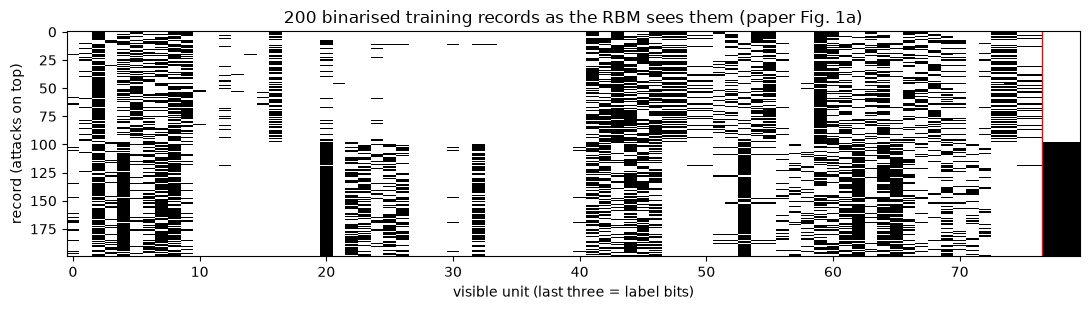

In [6]:
class Binarizer:
    """Fits the bit layout on training rows; transform() returns a uint8 matrix (rows x feature bits)."""
    def fit(self, X):
        self.spec, self.names = [], []
        for c in FEATURE_COLS:
            col = X[c]
            if c in NOMINAL_COLS:
                cats = sorted(col.unique())
                if len(cats) <= ONE_HOT_MAX:                                   # paper: one-hot for few distinct values
                    self.spec.append((c, "onehot", cats)); self.names += [f"{c}={v}" for v in cats]
                else:                                                          # paper: binary code for many distinct values
                    nb = int(np.ceil(np.log2(len(cats) + 1)))
                    self.spec.append((c, "bincode", (cats, nb))); self.names += [f"{c}_bit{i}" for i in range(nb)]
            else:
                vals = np.sort(col.unique().astype(float))
                if len(vals) <= 1:
                    continue                                                   # constant feature carries no information
                if len(vals) == 2 and set(vals) == {0.0, 1.0}:
                    self.spec.append((c, "bit", None)); self.names += [c]
                else:                                                          # paper: histogram bin index -> binary
                    edges = np.unique(np.quantile(col.to_numpy(float), np.linspace(0, 1, N_BINS + 1)[1:-1]))   # CHOICE: quantile edges
                    edges = edges[edges > vals[0]]                             # an edge at the minimum would leave the first bin empty
                    if len(edges) == 0:
                        edges = np.array([vals[1]])                            # very skewed feature: zero vs non-zero
                    nb = max(1, int(np.ceil(np.log2(len(edges) + 1))))
                    self.spec.append((c, "digitize", (edges, nb))); self.names += [f"{c}_bin{i}" for i in range(nb)]
        return self
    def transform(self, X):
        cols = []
        for c, kind, p in self.spec:
            col = X[c]
            if kind == "onehot":
                cols += [(col == v).to_numpy(np.uint8) for v in p]
            elif kind == "bincode":
                idx = pd.Categorical(col, categories=p[0]).codes.astype(int) + 1          # unseen value -> code 0
                cols += [((idx >> i) & 1).astype(np.uint8) for i in range(p[1])]
            elif kind == "bit":
                cols.append((col.to_numpy(float) > 0).astype(np.uint8))
            else:
                idx = np.digitize(col.to_numpy(float), p[0])
                cols += [((idx >> i) & 1).astype(np.uint8) for i in range(p[1])]
        return np.stack(cols, axis=1)

binarizer = Binarizer().fit(train_bal.iloc[idx_tr][FEATURE_COLS])              # fitted on the training rows only
X_bits_bal = binarizer.transform(train_bal[FEATURE_COLS])
X_bits_B = binarizer.transform(test_raw[FEATURE_COLS])
N_FEAT = X_bits_bal.shape[1]; N_VIS = N_FEAT + N_LABEL_BITS; N_UNITS = N_VIS + N_HIDDEN

def with_label_bits(X_bits, y):
    """Visible vectors: feature bits followed by the label written N_LABEL_BITS times (benign 111, attack 000)."""
    return np.concatenate([X_bits, np.repeat(y[:, None], N_LABEL_BITS, axis=1).astype(np.uint8)], axis=1).astype(np.float64)

V_train = with_label_bits(X_bits_bal[idx_tr], y_bal[idx_tr])
X_val, y_val = X_bits_bal[idx_val].astype(np.float64), y_bal[idx_val]
X_test_A, y_test_A = X_bits_bal[idx_A].astype(np.float64), y_bal[idx_A]
X_test_B = X_bits_B.astype(np.float64)
kinds = pd.Series([s[1] for s in binarizer.spec]).value_counts().to_dict()
print(f"{N_FEAT} feature bits + {N_LABEL_BITS} label bits = {N_VIS} visible units (paper: 85) | {N_HIDDEN} hidden units | {N_UNITS} units in total")
print("encoding per raw feature:", kinds, "| dropped as constant:", [c for c in FEATURE_COLS if c not in {s[0] for s in binarizer.spec}])
print("V_train", V_train.shape, "| X_val", X_val.shape, "| X_test_A", X_test_A.shape, "| X_test_B", X_test_B.shape)

fig, ax = plt.subplots(figsize=(11, 3.2))
order = np.argsort(y_bal[idx_tr][:200], kind="stable")
ax.imshow(V_train[:200][order], aspect="auto", cmap="Greys", interpolation="nearest")
ax.axvline(N_FEAT - 0.5, color="red", lw=1); ax.set_xlabel("visible unit (last three = label bits)"); ax.set_ylabel("record (attacks on top)")
ax.set_title("200 binarised training records as the RBM sees them (paper Fig. 1a)"); plt.tight_layout(); plt.show()

## 4. The restricted Boltzmann machine (Methods, Eq. 1-6) and contrastive divergence

The class below is the whole model: energy (Eq. 1), the two conditionals (Eq. 3-4), Gibbs sampling, and the gradient
step (Eq. 5-6) with the positive phase from the data batch and the negative phase from samples. Two sources of
samples are implemented:

* **CD-k** (`cd_update`): k Gibbs steps starting from the data batch (the classical RBM);
* **external sampler** (`sampler_update`): any function that returns $s$ joint $(v, h)$ samples of the current model,
  which is how the annealer (or its stand-in, Section 8) plugs in. Note that these samples do not depend on the batch,
  so the quantum negative phase costs the same for a batch of 1 or 1,000 records.

Classification follows the paper: load the feature bits into the visible layer, let the model reconstruct the three
label bits with k clamped Gibbs steps (the feature bits are reset to the data after each step; the label bits start at
random), and take the majority of the three reconstructed label probabilities. A second read-out, `classify_exact`,
computes $P(\text{label bits} \mid \text{feature bits})$ **exactly** by summing out the hidden units analytically (the
RBM free energy), which is the $k \to \infty$ limit of the reconstruction and costs eight matrix products. This cheap
exact read-out matters for the paper's exploitation-time argument (Section 11).

In [7]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

LABEL_PATTERNS = np.array([[(c >> i) & 1 for i in range(N_LABEL_BITS)] for c in range(2 ** N_LABEL_BITS)], np.float64)

class RBM:
    def __init__(self, n_vis=N_VIS, n_hid=N_HIDDEN, seed=SEED, w_std=W_INIT_STD):
        self.rng = np.random.default_rng(seed)
        self.W = self.rng.normal(0.0, w_std, (n_vis, n_hid))     # CHOICE: N(0, 0.01) weights, zero biases
        self.a = np.zeros(n_vis); self.b = np.zeros(n_hid)
    def p_h(self, v):  return sigmoid(self.b + v @ self.W)          # Eq. 4
    def p_v(self, h):  return sigmoid(self.a + h @ self.W.T)        # Eq. 3
    def energy(self, v, h):                                          # Eq. 1
        return -(v @ self.a + h @ self.b + np.einsum("ni,ij,nj->n", v, self.W, h))
    def free_energy(self, v):                                        # -log sum_h exp(-E(v,h))
        return -(v @ self.a + np.logaddexp(0.0, self.b + v @ self.W).sum(1))
    def gibbs(self, v, k, clamp=None):
        """k steps v -> h -> v. Returns (v_k, P(v|h_k), h_k). clamp: boolean mask of visible units reset to their input value after every step."""
        v0, nh = v, self.W.shape[1]
        for _ in range(k):
            u = self.rng.random((len(v), nh + self.W.shape[0]))          # one draw of uniforms per step
            h = (u[:, :nh] < self.p_h(v)).astype(np.float64)
            pv = self.p_v(h); v = (u[:, nh:] < pv).astype(np.float64)
            if clamp is not None:
                v[:, clamp] = v0[:, clamp]
        return v, pv, h
    def _ascent(self, v0, ph0, vk, hk, lr):                          # Eq. 5-6: positive phase (data) minus negative phase (model samples)
        self.W += lr * (v0.T @ ph0 / len(v0) - vk.T @ hk / len(vk))
        self.a += lr * (v0.mean(0) - vk.mean(0)); self.b += lr * (ph0.mean(0) - hk.mean(0))
    def cd_update(self, v0, k, lr):
        """Classical CD-k: the Gibbs chain starts at the data batch. Returns the time spent on the negative phase (the k Gibbs steps)."""
        ph0 = self.p_h(v0)
        t0 = time.perf_counter(); vk, _, _ = self.gibbs(v0, k); t_neg = time.perf_counter() - t0
        self._ascent(v0, ph0, vk, self.p_h(vk), lr)
        return t_neg
    def sampler_update(self, v0, lr, sampler_fn):
        """Negative phase from an external sampler returning s joint (v, h) samples of the current model (annealer or stand-in)."""
        ph0 = self.p_h(v0)
        t0 = time.perf_counter(); vk, hk = sampler_fn(self); t_neg = time.perf_counter() - t0
        self._ascent(v0, ph0, vk, hk, lr)
        return t_neg
    def classify(self, X_feat, k):
        """Paper's read-out: clamp the feature bits, k Gibbs steps, majority vote over the three reconstructed label bits."""
        v = np.concatenate([X_feat, (self.rng.random((len(X_feat), N_LABEL_BITS)) < 0.5).astype(np.float64)], axis=1)   # CHOICE: label bits start at random
        clamp = np.zeros(N_VIS, bool); clamp[:N_FEAT] = True
        _, pv, _ = self.gibbs(v, k, clamp=clamp)
        return (pv[:, N_FEAT:].mean(1) > 0.5).astype(int)
    def classify_exact(self, X_feat):
        """Exact P(label bits | feature bits): hidden units summed out analytically (k -> infinity limit of classify)."""
        logp = np.stack([-self.free_energy(np.concatenate([X_feat, np.tile(pat, (len(X_feat), 1))], axis=1)) for pat in LABEL_PATTERNS], axis=1)
        p = np.exp(logp - logp.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
        return ((p @ LABEL_PATTERNS).mean(1) > 0.5).astype(int)

def metrics(y_true, y_pred):
    """Paper's six metrics with the attack (label 0) as positive class; TP/FP/FN/TN normalised as in Tables 1-2 (TP+FN = 1, FP+TN = 1)."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    return dict(accuracy=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, pos_label=0),
                TP=tp / (tp + fn), FP=fp / (fp + tn), FN=fn / (tp + fn), TN=tn / (fp + tn))

def train_rbm(k=None, sampler_fn=None, lr=0.1, seed=SEED, n_updates=N_UPDATES, eval_every=EVAL_EVERY, verbose=False):
    """Trains on V_train for n_updates mini-batch updates; records the validation accuracy (exact read-out) every eval_every updates."""
    rbm = RBM(seed=seed); draw = np.random.default_rng(seed + 1000)
    curve, t_neg, t0 = [], 0.0, time.perf_counter()
    for u in range(1, n_updates + 1):
        batch = V_train[draw.integers(0, len(V_train), BATCH_SIZE)]
        t_neg += rbm.cd_update(batch, k, lr) if sampler_fn is None else rbm.sampler_update(batch, lr, sampler_fn)
        if u % eval_every == 0 or u == n_updates:
            curve.append(dict(update=u, val_accuracy=accuracy_score(y_val, rbm.classify_exact(X_val))))
            if verbose and u % (10 * eval_every) == 0:
                print(f"   update {u}: validation accuracy {curve[-1]['val_accuracy']:.3f}")
    return rbm, pd.DataFrame(curve), time.perf_counter() - t0, t_neg

# sanity check of the free energy on a tiny model (6 visible, 4 hidden): brute-force sum over the 16 hidden states
tiny = RBM(n_vis=6, n_hid=4, seed=0); r0 = np.random.default_rng(0)
tiny.W[:] = r0.normal(0, 1, tiny.W.shape); tiny.a[:] = r0.normal(0, 1, 6); tiny.b[:] = r0.normal(0, 1, 4)
v_all = np.array(list(itertools.product([0, 1], repeat=6)), np.float64); h_all = np.array(list(itertools.product([0, 1], repeat=4)), np.float64)
F_brute = np.array([-np.log(np.exp(-tiny.energy(np.tile(v, (16, 1)), h_all)).sum()) for v in v_all])
assert np.allclose(F_brute, tiny.free_energy(v_all)), "free energy mismatch"
print("free_energy() equals the brute-force -log sum_h exp(-E(v,h)) on all 64 visible states of a toy RBM: True")

free_energy() equals the brute-force -log sum_h exp(-E(v,h)) on all 64 visible states of a toy RBM: True


## 5. Learning rate on the validation slice

The paper's learning rate is in its supplementary table, which is not part of the article. Rather than guessing, the
candidates in `LR_GRID` are compared with CD-1 on the validation slice of the training rows (the test sets are not
involved) and the winner is used for every RBM and for the stand-in QRBM below.

In [8]:
lr_rows = []
for lr in LR_GRID:
    rbm_lr, curve_lr, t_lr, _ = train_rbm(k=1, lr=lr, seed=SEED, n_updates=N_UPDATES)
    lr_rows.append(dict(learning_rate=lr, val_accuracy_exact=curve_lr["val_accuracy"].iloc[-1],
                        val_accuracy_k10=accuracy_score(y_val, rbm_lr.classify(X_val, 10)), seconds=round(t_lr, 1)))
lr_df = pd.DataFrame(lr_rows); display(lr_df)
LR = float(lr_df.sort_values(["val_accuracy_k10", "val_accuracy_exact"], ascending=False)["learning_rate"].iloc[0])   # CHOICE: best validation accuracy (k = 10 read-out)
print("learning rate used from here on:", LR)

,learning_rate,val_accuracy_exact,val_accuracy_k10,seconds
0,0.05,0.965888,0.953949,7.7
1,0.10,0.971005,0.968553,11.6
2,0.20,0.979320,0.974843,9.7
3,0.50,0.981025,0.970259,8.6


learning rate used from here on: 0.2


## 6. Classical baselines on identical inputs

The paper has no classical-ML baseline. To know what the bit representation itself allows, a random forest, an RBF
support-vector machine (on a random subset of the training rows, its cost being quadratic) and a logistic regression
are trained on exactly the same feature bits and evaluated under both protocols.

In [9]:
def eval_both(predict_fn):
    return {"A (hold-out)": metrics(y_test_A, predict_fn(X_test_A)), "B (KDDTest+)": metrics(y_test_B, predict_fn(X_test_B))}

X_train_feat, y_train_feat = V_train[:, :N_FEAT], y_bal[idx_tr]
sub = np.random.default_rng(SEED).choice(len(X_train_feat), min(N_SVC_TRAIN, len(X_train_feat)), replace=False)
baseline_models = {
    "RandomForest (200 trees)": (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2), slice(None)),
    f"SVC (rbf, C=1, {len(sub):,} rows)": (SVC(kernel="rbf", C=1.0, gamma="scale"), sub),       # CHOICE: defaults, subset of rows
    "LogisticRegression": (LogisticRegression(max_iter=2000), slice(None)),
}
baseline_rows, baseline_preds = [], {}
for name, (model, rows) in baseline_models.items():
    t0 = time.perf_counter(); model.fit(X_train_feat[rows], y_train_feat[rows]); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); res = eval_both(model.predict); t_pred = time.perf_counter() - t0
    baseline_preds[name] = model.predict(X_test_A), model.predict(X_test_B)
    for proto, m in res.items():
        baseline_rows.append(dict(model=name, protocol=proto, fit_s=round(t_fit, 1), predict_s=round(t_pred, 1), **{k: round(v, 3) for k, v in m.items()}))
baseline_df = pd.DataFrame(baseline_rows); display(baseline_df)

,model,protocol,fit_s,predict_s,accuracy,f1,TP,FP,FN,TN
0,RandomForest (200 trees),A (hold-out),18.7,0.7,0.997,0.997,0.997,0.003,0.003,0.997
1,RandomForest (200 trees),B (KDDTest+),18.7,0.7,0.768,0.751,0.613,0.027,0.387,0.973
2,"SVC (rbf, C=1, 20,000 rows)",A (hold-out),3.6,9.7,0.993,0.993,0.991,0.005,0.009,0.995
3,"SVC (rbf, C=1, 20,000 rows)",B (KDDTest+),3.6,9.7,0.799,0.791,0.669,0.029,0.331,0.971
4,LogisticRegression,A (hold-out),1.5,0.0,0.981,0.981,0.978,0.015,0.022,0.985
5,LogisticRegression,B (KDDTest+),1.5,0.0,0.746,0.734,0.615,0.080,0.385,0.920


## 7. The classical RBM: training k (Fig. 5) and exploitation k (Table 1)

For every training k in `K_TRAIN_LIST` and every seed an RBM is trained with CD-k for `N_UPDATES` updates. Fig. 5 of the
paper plots the test F1 and accuracy against the training k with a 95 % confidence band over runs; here the read-out
uses k = 10 clamped Gibbs steps (the paper does not say which exploitation k Fig. 5 uses) and both protocols are
shown. The learning curves (validation accuracy vs update) are kept for Section 9.

Table 1 of the paper varies k **during exploitation** for a trained model. The cell after the figure takes the models
trained with CD-`K_TABLE1_TRAIN` and reads the label bits out with every k in `K_EXPLOIT_LIST`, plus the exact read-out
as the k -> infinity reference.

CD-1    seed 42:   10.9 s (   1.1 s in the negative phase) | A acc 0.974 F1 0.973 | B acc 0.758 F1 0.744


CD-1    seed 43:   11.5 s (   1.2 s in the negative phase) | A acc 0.974 F1 0.973 | B acc 0.742 F1 0.728


CD-1    seed 44:   10.8 s (   1.1 s in the negative phase) | A acc 0.972 F1 0.971 | B acc 0.752 F1 0.739


CD-10   seed 42:   21.5 s (  11.5 s in the negative phase) | A acc 0.971 F1 0.970 | B acc 0.758 F1 0.745


CD-10   seed 43:   18.2 s (   8.8 s in the negative phase) | A acc 0.976 F1 0.976 | B acc 0.752 F1 0.740


...

CD-100  seed 44:   90.4 s (  82.1 s in the negative phase) | A acc 0.972 F1 0.972 | B acc 0.751 F1 0.736


CD-1000 seed 42:  780.9 s ( 773.2 s in the negative phase) | A acc 0.970 F1 0.970 | B acc 0.764 F1 0.750


CD-1000 seed 43:  804.9 s ( 797.0 s in the negative phase) | A acc 0.962 F1 0.963 | B acc 0.781 F1 0.780


CD-1000 seed 44:  605.4 s ( 599.0 s in the negative phase) | A acc 0.967 F1 0.966 | B acc 0.730 F1 0.710

Fig. 5 / training-k sweep (mean over seeds, read-out k = 10):


,protocol,k_train,accuracy,accuracy_std,f1,f1_std,train_s,negative_phase_s
0,A (hold-out),1,0.9730,0.0012,0.9727,0.0011,11.0575,1.1099
1,A (hold-out),10,0.9722,0.0034,0.9720,0.0034,19.3411,9.7414
2,A (hold-out),100,0.9722,0.0007,0.9720,0.0006,83.4255,75.5678
3,A (hold-out),1000,0.9663,0.0037,0.9661,0.0034,730.3829,723.0841
4,B (KDDTest+),1,0.7506,0.0083,0.7371,0.0082,11.0575,1.1099
5,B (KDDTest+),10,0.7677,0.0228,0.7590,0.0287,19.3411,9.7414
6,B (KDDTest+),100,0.7623,0.0115,0.7516,0.0141,83.4255,75.5678
7,B (KDDTest+),1000,0.7581,0.0257,0.7468,0.0350,730.3829,723.0841


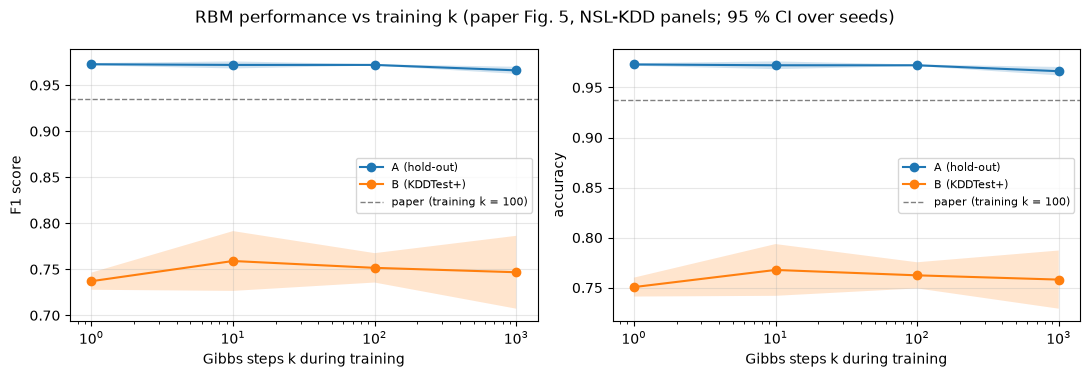

In [10]:
rbm_models, fig5_rows, curves = {}, [], {}
for k in K_TRAIN_LIST:
    for s in range(N_SEEDS):
        t_start = time.perf_counter()
        rbm, curve, t_train, t_neg = train_rbm(k=k, lr=LR, seed=SEED + s)
        rbm_models[(k, s)] = rbm; curves[("CD-%d" % k, s)] = curve
        res = eval_both(lambda X: rbm.classify(X, 10))
        for proto, m in res.items():
            fig5_rows.append(dict(k_train=k, seed=SEED + s, protocol=proto, train_s=t_train, negative_phase_s=t_neg, **m))
        print(f"CD-{k:<4d} seed {SEED+s}: {t_train:6.1f} s ({t_neg:6.1f} s in the negative phase) | "
              f"A acc {res['A (hold-out)']['accuracy']:.3f} F1 {res['A (hold-out)']['f1']:.3f} | B acc {res['B (KDDTest+)']['accuracy']:.3f} F1 {res['B (KDDTest+)']['f1']:.3f}")
fig5_df = pd.DataFrame(fig5_rows)
fig5_summary = fig5_df.groupby(["protocol", "k_train"]).agg(accuracy=("accuracy", "mean"), accuracy_std=("accuracy", "std"), f1=("f1", "mean"), f1_std=("f1", "std"),
                                                             train_s=("train_s", "mean"), negative_phase_s=("negative_phase_s", "mean")).reset_index()
print("\nFig. 5 / training-k sweep (mean over seeds, read-out k = 10):"); display(fig5_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for proto, g in fig5_summary.groupby("protocol"):
    for ax, met in zip(axes, ["f1", "accuracy"]):
        ci = 1.96 * g[met + "_std"].fillna(0) / np.sqrt(N_SEEDS)
        ax.plot(g["k_train"], g[met], "o-", label=proto); ax.fill_between(g["k_train"], g[met] - ci, g[met] + ci, alpha=0.2)
for ax, met in zip(axes, ["F1 score", "accuracy"]):
    ax.axhline(0.935 if met == "F1 score" else 0.937, color="gray", ls="--", lw=1, label="paper (training k = 100)")
    ax.set_xscale("log"); ax.set_xlabel("Gibbs steps k during training"); ax.set_ylabel(met); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("RBM performance vs training k (paper Fig. 5, NSL-KDD panels; 95 % CI over seeds)"); plt.tight_layout(); plt.show()

In [11]:
table1_rows = []
for k_ex in K_EXPLOIT_LIST + ["exact"]:
    for s in range(N_SEEDS):
        rbm = rbm_models[(K_TABLE1_TRAIN, s)]
        t0 = time.perf_counter()
        res = eval_both((lambda X: rbm.classify_exact(X)) if k_ex == "exact" else (lambda X: rbm.classify(X, k_ex)))
        t_pred = time.perf_counter() - t0
        for proto, m in res.items():
            table1_rows.append(dict(k_exploit=str(k_ex), seed=SEED + s, protocol=proto, predict_s=t_pred, **m))
table1_df = pd.DataFrame(table1_rows)
table1_summary = table1_df.groupby(["protocol", "k_exploit"], sort=False).agg(**{m: (m, "mean") for m in ["accuracy", "f1", "TP", "FP", "FN", "TN"]},
                                                                                accuracy_std=("accuracy", "std"), predict_s=("predict_s", "mean")).reset_index()
print(f"Table 1 (NSL-KDD): models trained with CD-{K_TABLE1_TRAIN}, read-out with k exploitation Gibbs steps (mean over {N_SEEDS} seeds); predict_s is for both test sets together")
display(table1_summary.round(4))

Table 1 (NSL-KDD): models trained with CD-10, read-out with k exploitation Gibbs steps (mean over 3 seeds); predict_s is for both test sets together


,protocol,k_exploit,accuracy,f1,TP,FP,FN,TN,accuracy_std,predict_s
0,A (hold-out),1,0.9103,0.9121,0.9282,0.1076,0.0718,0.8924,0.0159,0.2435
1,B (KDDTest+),1,0.7399,0.7420,0.6581,0.1519,0.3419,0.8481,0.0147,0.2435
2,A (hold-out),10,0.9719,0.9717,0.9636,0.0197,0.0364,0.9803,0.0035,2.1415
3,B (KDDTest+),10,0.7670,0.7582,0.6430,0.0690,0.3570,0.9310,0.0227,2.1415
4,A (hold-out),100,0.9734,0.9732,0.9644,0.0175,0.0356,0.9825,0.0031,20.8741
5,B (KDDTest+),100,0.7630,0.7539,0.6391,0.0732,0.3609,0.9268,0.0224,20.8741
6,A (hold-out),1000,0.9734,0.9732,0.9644,0.0176,0.0356,0.9824,0.0028,205.6577
7,B (KDDTest+),1000,0.7626,0.7536,0.6389,0.0739,0.3611,0.9261,0.0219,205.6577
8,A (hold-out),exact,0.9761,0.9759,0.9656,0.0134,0.0344,0.9866,0.0027,0.6013
9,B (KDDTest+),exact,0.7590,0.7494,0.6354,0.0777,0.3646,0.9223,0.0270,0.6013


## 8. The quantum negative phase: the annealer and its stand-in

The paper's QRBM changes exactly one thing: the negative-phase samples come from the D-Wave Advantage annealer instead
of a Gibbs chain. The RBM energy is a quadratic function of binary variables, i.e. a QUBO / binary quadratic model
(BQM) with linear terms $-a_i$, $-b_j$ and couplers $-W_{ij}$; D-Wave's software stack represents it with
`dimod.BinaryQuadraticModel`, embeds it on the chip and the anneal returns low-energy $(v, h)$ configurations that, at
the freeze-out point, are distributed as $e^{-E/T_{eff}}$ (Eq. 7). The paper rescales the energies by $\alpha$ so that
$T_{eff} = 1$ and takes **10 samples per update**.

Without a QPU the notebook uses D-Wave's `SimulatedAnnealingSampler` from `dwave-samplers` on the **same BQM**: a
Metropolis annealing schedule from $\beta = 0.1$ to $\beta = 1$ (`SA_BETA_RANGE`), `SA_SWEEPS` sweeps, `QPU_SAMPLES`
reads. The read-out happens at $\beta = 1$, so the stand-in samples the Boltzmann distribution at temperature 1 (the
paper's target after $\alpha$ rescaling) without any effective-temperature drift to track. This is a classical
algorithm: it reproduces *what the annealer samples*, not *how fast*. If `dwave-samplers` cannot be imported, a small
numpy annealer with the same interface is used.

**Check on a toy RBM.** For 6 visible and 4 hidden units the 1,024 states can be enumerated, so the exact
$P(v)$ is known. The cell compares it with 5,000 stand-in samples and with Gibbs chains of k = 1, 10, 100 steps started
from random states (total-variation distance; the sampling noise floor of 5,000 draws over 64 states is about 0.03).

BQM energies equal the RBM energies (Eq. 1) on all 1,024 toy states: True
stand-in: 5000 reads in 0.03 s | TV distance to the exact P(v): {'stand-in (SA, beta -> 1)': np.float64(0.028), 'Gibbs chain, k = 1 (random start)': np.float64(0.129), 'Gibbs chain, k = 10 (random start)': np.float64(0.03), 'Gibbs chain, k = 100 (random start)': np.float64(0.025)}


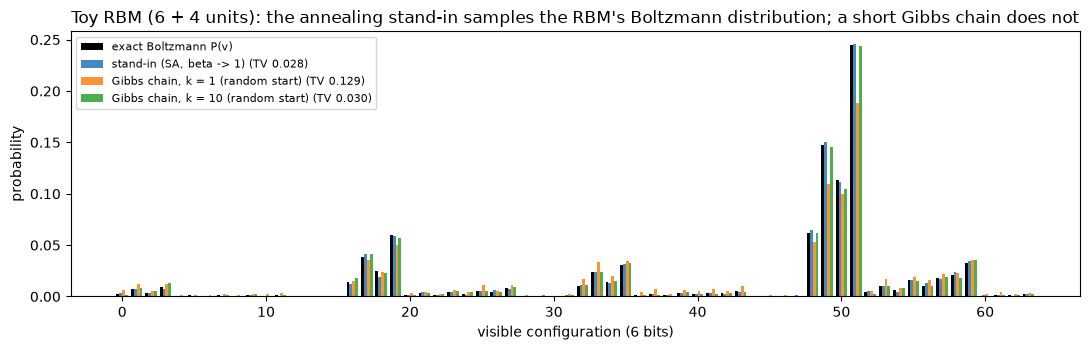

In [12]:
def rbm_to_bqm(rbm, alpha=ALPHA):
    """RBM energy (Eq. 1) as a dimod BinaryQuadraticModel: variables 0..N_VIS-1 are visible units, N_VIS.. are hidden units."""
    nv, nh = rbm.W.shape; Q = np.zeros((nv + nh, nv + nh))
    Q[np.arange(nv), np.arange(nv)] = -alpha * rbm.a; Q[nv + np.arange(nh), nv + np.arange(nh)] = -alpha * rbm.b
    Q[:nv, nv:] = -alpha * rbm.W
    return dimod.BinaryQuadraticModel(Q, dimod.BINARY)

class NumpySASampler:
    """Fallback with dimod's call signature: single-spin-flip Metropolis annealing on a BQM (geometric beta schedule)."""
    def sample(self, bqm, num_reads=10, num_sweeps=20, beta_range=(0.1, 1.0), seed=None):
        labels = sorted(bqm.variables); n = len(labels)
        h, (row, col, quad), _ = bqm.to_numpy_vectors(variable_order=labels)
        J = np.zeros((n, n)); J[row, col] = quad; J += J.T
        r = np.random.default_rng(seed); x = (r.random((num_reads, n)) < 0.5).astype(np.float64)
        for beta in np.geomspace(beta_range[0], beta_range[1], num_sweeps):
            for i in r.permutation(n):
                dE = (1 - 2 * x[:, i]) * (h[i] + x @ J[i])
                flip = r.random(num_reads) < np.exp(-beta * np.clip(dE, 0, None))
                x[flip, i] = 1 - x[flip, i]
        return dimod.SampleSet.from_samples((x, labels), dimod.BINARY, energy=bqm.energies((x, labels)))

sampler = SimulatedAnnealingSampler() if SimulatedAnnealingSampler is not None else NumpySASampler()
_sa_seed = [SEED]
def annealer_samples(rbm, num_reads=QPU_SAMPLES, num_sweeps=SA_SWEEPS, beta_range=SA_BETA_RANGE):
    """Stand-in for one QPU call: num_reads joint (v, h) samples of the current RBM at effective temperature 1."""
    _sa_seed[0] += 1
    ss = sampler.sample(rbm_to_bqm(rbm), num_reads=num_reads, num_sweeps=num_sweeps, beta_range=beta_range, seed=_sa_seed[0])
    order = np.argsort(np.asarray(list(ss.variables)))                       # columns in unit order 0..N-1
    arr = ss.record.sample[:, order].astype(np.float64)
    nv = rbm.W.shape[0]
    return arr[:, :nv], arr[:, nv:]

# ---- toy check against the exact Boltzmann distribution
nv_t, nh_t = 6, 4
toy = RBM(n_vis=nv_t, n_hid=nh_t, seed=0); r0 = np.random.default_rng(0)
toy.W[:] = r0.normal(0, 1, (nv_t, nh_t)); toy.a[:] = r0.normal(0, 1, nv_t); toy.b[:] = r0.normal(0, 1, nh_t)
states = np.array(list(itertools.product([0, 1], repeat=nv_t + nh_t)), np.float64)
p_joint = np.exp(-toy.energy(states[:, :nv_t], states[:, nv_t:])); p_joint /= p_joint.sum()
code_of = lambda V: (V @ (2 ** np.arange(nv_t)[::-1])).astype(int)
p_exact = np.bincount(code_of(states[:, :nv_t]), weights=p_joint, minlength=2 ** nv_t)
bqm_toy = rbm_to_bqm(toy)
assert np.allclose(bqm_toy.energies((states, list(range(nv_t + nh_t)))), toy.energy(states[:, :nv_t], states[:, nv_t:])), "BQM energy != RBM energy"
print("BQM energies equal the RBM energies (Eq. 1) on all 1,024 toy states: True")

tv = lambda p, q: 0.5 * np.abs(p - q).sum()
n_draws, dist = 5000, {}
t0 = time.perf_counter(); v_sa, _ = annealer_samples(toy, num_reads=n_draws); t_sa = time.perf_counter() - t0
dist["stand-in (SA, beta -> 1)"] = np.bincount(code_of(v_sa), minlength=2 ** nv_t) / n_draws
v = (np.random.default_rng(1).random((n_draws, nv_t)) < 0.5).astype(np.float64)
for k in [1, 10, 100]:
    vk, _, _ = toy.gibbs(v, k); dist[f"Gibbs chain, k = {k} (random start)"] = np.bincount(code_of(vk), minlength=2 ** nv_t) / n_draws
print(f"stand-in: {n_draws} reads in {t_sa:.2f} s | TV distance to the exact P(v):", {k: round(tv(p, p_exact), 3) for k, p in dist.items()})

fig, ax = plt.subplots(figsize=(11, 3.6)); x = np.arange(2 ** nv_t); w = 0.2
ax.bar(x - 1.5 * w, p_exact, w, label="exact Boltzmann P(v)", color="black")
for i, (name, p) in enumerate(dist.items()):
    if i < 3: ax.bar(x + (i - 0.5) * w, p, w, label=name + f" (TV {tv(p, p_exact):.3f})", alpha=0.85)
ax.set_xlabel("visible configuration (6 bits)"); ax.set_ylabel("probability"); ax.legend(fontsize=8)
ax.set_title("Toy RBM (6 + 4 units): the annealing stand-in samples the RBM's Boltzmann distribution; a short Gibbs chain does not"); plt.tight_layout(); plt.show()

## 9. Training the QRBM with the stand-in (Table 2) and "epochs to a target accuracy" (Suppl. Table 3)

Same data, same model, same learning rate, same number of updates; only the negative phase changes: 10 reads of the
stand-in per update instead of a Gibbs chain. The read-out uses k = 10 clamped Gibbs steps as for the classical RBM
(Table 2 of the paper does not say how the QRBM was queried; Section 11 shows that the exact read-out gives the same
numbers). The learning curves of the CD-1 RBM and of the QRBM on the validation slice give the number of updates needed
to reach `TARGET_ACC`, the paper's Supplementary-Table-3 quantity.

QRBM stand-in seed 42:    9.8 s (   4.9 s in 2000 sampler calls) | A acc 0.970 F1 0.969 | B acc 0.742 F1 0.725


QRBM stand-in seed 43:   10.3 s (   5.1 s in 2000 sampler calls) | A acc 0.971 F1 0.971 | B acc 0.747 F1 0.735


QRBM stand-in seed 44:   10.0 s (   4.9 s in 2000 sampler calls) | A acc 0.974 F1 0.973 | B acc 0.759 F1 0.752

Table 2 (NSL-KDD), stand-in QRBM, read-out k = 10:


,protocol,accuracy,f1,TP,FP,FN,TN,accuracy_std,f1_std
0,A (hold-out),0.9716,0.9712,0.9580,0.0149,0.0420,0.9851,0.0018,0.0020
1,B (KDDTest+),0.7493,0.7372,0.6183,0.0776,0.3817,0.9224,0.0087,0.0133


updates needed to reach a validation accuracy of 0.93 (mean curve over seeds; exact read-out):


,model,updates_to_target,final_val_accuracy
0,CD-1,400,0.9783
1,CD-10,350,0.9781
2,CD-100,350,0.9791
3,CD-1000,350,0.9743
4,QRBM stand-in,300,0.9734


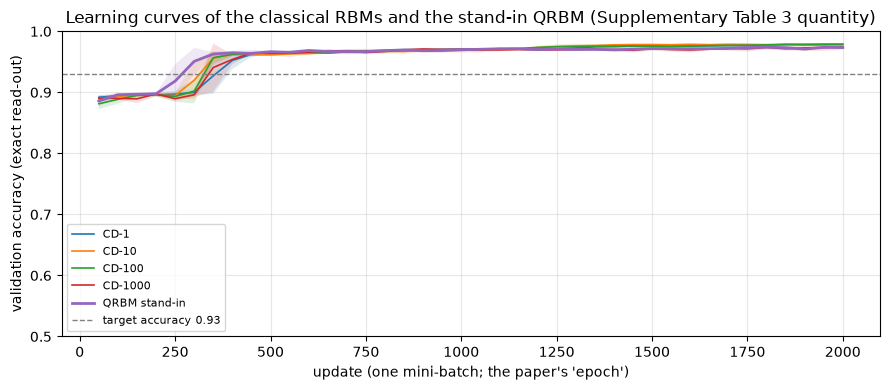

In [13]:
qrbm_models, table2_rows = {}, []
for s in range(N_SEEDS):
    qrbm, curve, t_train, t_neg = train_rbm(sampler_fn=annealer_samples, lr=LR, seed=SEED + s)
    qrbm_models[s] = qrbm; curves[("QRBM stand-in", s)] = curve
    res = eval_both(lambda X: qrbm.classify(X, 10))
    for proto, m in res.items():
        table2_rows.append(dict(model="QRBM (stand-in, %d samples/update)" % QPU_SAMPLES, seed=SEED + s, protocol=proto, train_s=t_train, negative_phase_s=t_neg, **m))
    print(f"QRBM stand-in seed {SEED+s}: {t_train:6.1f} s ({t_neg:6.1f} s in {N_UPDATES} sampler calls) | "
          f"A acc {res['A (hold-out)']['accuracy']:.3f} F1 {res['A (hold-out)']['f1']:.3f} | B acc {res['B (KDDTest+)']['accuracy']:.3f} F1 {res['B (KDDTest+)']['f1']:.3f}")
table2_df = pd.DataFrame(table2_rows)
table2_summary = table2_df.groupby("protocol").agg(**{m: (m, "mean") for m in ["accuracy", "f1", "TP", "FP", "FN", "TN"]}, accuracy_std=("accuracy", "std"), f1_std=("f1", "std")).reset_index()
print("\nTable 2 (NSL-KDD), stand-in QRBM, read-out k = 10:"); display(table2_summary.round(4))

# learning curves and updates-to-target (Supplementary Table 3)
curve_df = pd.concat([c.assign(model=m, seed=s) for (m, s), c in curves.items()])
curve_mean = curve_df.groupby(["model", "update"])["val_accuracy"].agg(["mean", "std"]).reset_index()
epochs_rows = []
for m, g in curve_mean.groupby("model"):
    hit = g[g["mean"] >= TARGET_ACC]
    epochs_rows.append(dict(model=m, updates_to_target=int(hit["update"].iloc[0]) if len(hit) else None, final_val_accuracy=round(g["mean"].iloc[-1], 4)))
epochs_df = pd.DataFrame(epochs_rows)
print(f"updates needed to reach a validation accuracy of {TARGET_ACC} (mean curve over seeds; exact read-out):"); display(epochs_df)

fig, ax = plt.subplots(figsize=(9, 4))
for m, g in curve_mean.groupby("model"):
    ax.plot(g["update"], g["mean"], label=m, lw=2 if "QRBM" in m else 1.2)
    ax.fill_between(g["update"], g["mean"] - 1.96 * g["std"].fillna(0) / np.sqrt(N_SEEDS), g["mean"] + 1.96 * g["std"].fillna(0) / np.sqrt(N_SEEDS), alpha=0.15)
ax.axhline(TARGET_ACC, color="gray", ls="--", lw=1, label=f"target accuracy {TARGET_ACC}")
ax.set_xlabel("update (one mini-batch; the paper's 'epoch')"); ax.set_ylabel("validation accuracy (exact read-out)"); ax.set_ylim(0.5, 1.0); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Learning curves of the classical RBMs and the stand-in QRBM (Supplementary Table 3 quantity)"); plt.tight_layout(); plt.show()

## 10. Querying the trained QRBM through the sampler

In the paper's exploitation phase the QRBM is queried by the annealer too: the feature bits are fixed and 10 samples
of the remaining units (3 label bits + 30 hidden units) are drawn. `dimod` fixes variables with `fix_variables`, which
folds the clamped bits into the biases of the remaining 33-variable BQM; one sampler call per record then votes over the
label bits of the 10 reads. This is done for `N_QPU_TEST` records of each test set and compared with the exact
conditional read-out of the same model, to show that the two routes agree.

In [14]:
def query_via_sampler(rbm, X_feat, num_reads=QPU_SAMPLES):
    bqm_full = rbm_to_bqm(rbm); preds, t0 = [], time.perf_counter()
    for row in X_feat:
        bqm = bqm_full.copy(); bqm.fix_variables({i: int(row[i]) for i in range(N_FEAT)})       # clamp the feature bits
        _sa_seed[0] += 1
        ss = sampler.sample(bqm, num_reads=num_reads, num_sweeps=SA_SWEEPS, beta_range=SA_BETA_RANGE, seed=_sa_seed[0])
        lab_cols = [list(ss.variables).index(N_FEAT + j) for j in range(N_LABEL_BITS)]
        preds.append(int(ss.record.sample[:, lab_cols].mean() > 0.5))                           # majority vote over 10 reads x 3 label bits
    return np.array(preds), time.perf_counter() - t0

qrbm0 = qrbm_models[0]; sub_rows = np.random.default_rng(SEED).choice(len(y_test_A), N_QPU_TEST, replace=False)
sub_rows_B = np.random.default_rng(SEED).choice(len(y_test_B), N_QPU_TEST, replace=False)
query_rows = []
for proto, X, y, rows in [("A (hold-out)", X_test_A, y_test_A, sub_rows), ("B (KDDTest+)", X_test_B, y_test_B, sub_rows_B)]:
    pred_q, t_q = query_via_sampler(qrbm0, X[rows]); pred_e = qrbm0.classify_exact(X[rows]); pred_g = qrbm0.classify(X[rows], 10)
    query_rows.append(dict(protocol=proto, rows=N_QPU_TEST, acc_sampler=accuracy_score(y[rows], pred_q), acc_exact=accuracy_score(y[rows], pred_e),
                           acc_gibbs_k10=accuracy_score(y[rows], pred_g), agreement_sampler_vs_exact=(pred_q == pred_e).mean(), ms_per_record=1000 * t_q / N_QPU_TEST))
display(pd.DataFrame(query_rows).round(3))

,protocol,rows,acc_sampler,acc_exact,acc_gibbs_k10,agreement_sampler_vs_exact,ms_per_record
0,A (hold-out),300,0.973,0.973,0.973,1.000,8.286
1,B (KDDTest+),300,0.750,0.743,0.740,0.993,8.260


## 11. Negative-phase timing (Fig. 2, Table 3)

Table 3 of the paper compares the time to evaluate the negative phase for the NSL-KDD model: 0.070 s for k = 10 on
one Threadripper core, 0.035 s on 128 threads, 0.016 s QPU access time for 10 samples. The cell measures, for the
model size trained above (`N_UNITS` units), the time of k Gibbs steps in this notebook's numpy implementation for a
batch of 100 records (what training uses) and for a single record (what the paper's Table 3 appears to time: a chain
per data point), and the time of one stand-in call with 10 reads (with and without rebuilding the BQM). The QPU access
time cannot be measured without the hardware; the paper's values are listed for reference only.

In [15]:
rbm_t = rbm_models[(K_TABLE1_TRAIN, 0)]
def time_cd(k, batch, repeats=TIMING_REPEATS):
    v = V_train[:batch]; rbm_t.gibbs(v, 1)                                     # warm-up
    t0 = time.perf_counter()
    for _ in range(repeats): rbm_t.gibbs(v, k)
    return (time.perf_counter() - t0) / repeats
bqm_t = rbm_to_bqm(rbm_t)
def time_sampler(rebuild, repeats=TIMING_REPEATS):
    t0 = time.perf_counter()
    for _ in range(repeats):
        b = rbm_to_bqm(rbm_t) if rebuild else bqm_t
        sampler.sample(b, num_reads=QPU_SAMPLES, num_sweeps=SA_SWEEPS, beta_range=SA_BETA_RANGE, seed=1)
    return (time.perf_counter() - t0) / repeats

timing_rows = [dict(processor="this CPU, numpy (1 record)", k_or_s=f"k = {k}", seconds=time_cd(k, 1)) for k in [1, 10, 100, 1000]]
timing_rows += [dict(processor="this CPU, numpy (batch of 100)", k_or_s=f"k = {k}", seconds=time_cd(k, 100)) for k in [1, 10, 100, 1000]]
timing_rows += [dict(processor=f"stand-in sampler ({SA_BACKEND}), sampling only", k_or_s=f"s = {QPU_SAMPLES}", seconds=time_sampler(False)),
                dict(processor=f"stand-in sampler ({SA_BACKEND}), incl. BQM build", k_or_s=f"s = {QPU_SAMPLES}", seconds=time_sampler(True)),
                dict(processor="paper: Threadripper 3990X, 1 core", k_or_s="k = 10", seconds=0.070),
                dict(processor="paper: Threadripper 3990X, 128 cores", k_or_s="k = 10", seconds=0.035),
                dict(processor="paper: D-Wave Advantage 4.1 (QPU access time)", k_or_s="s = 10", seconds=0.016)]
timing_df = pd.DataFrame(timing_rows); timing_df["seconds"] = timing_df["seconds"].map(lambda x: float(f"{x:.3g}"))
t_sa_only = timing_df.loc[timing_df.processor.str.contains("sampling only"), "seconds"].iloc[0]
timing_df["x stand-in time"] = (timing_df["seconds"] / t_sa_only).round(2)
print(f"Negative-phase time for the NSL-KDD model ({N_VIS} visible + {N_HIDDEN} hidden units); this CPU: {platform.processor() or platform.machine()}")
display(timing_df)
print(f"paper Table 3 speed-up (NSL-KDD, k = 10 vs 10 QPU samples): 4x single core, 2x 128 threads -> cannot be checked here (no QPU);"
      f" our CD-10 on one record takes {timing_df.seconds.iloc[1]*1000:.2f} ms, i.e. {0.070/timing_df.seconds.iloc[1]:.0f}x faster than the paper's single-core time for the same k")

Negative-phase time for the NSL-KDD model (80 visible + 30 hidden units); this CPU: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel


,processor,k_or_s,seconds,x stand-in time
0,"this CPU, numpy (1 record)",k = 1,0.000028,0.01
1,"this CPU, numpy (1 record)",k = 10,0.000263,0.13
2,"this CPU, numpy (1 record)",k = 100,0.002160,1.06
3,"this CPU, numpy (1 record)",k = 1000,0.020600,10.15
4,"this CPU, numpy (batch of 100)",k = 1,0.000183,0.09
5,"this CPU, numpy (batch of 100)",k = 10,0.001830,0.90
6,"this CPU, numpy (batch of 100)",k = 100,0.019900,9.80
7,"this CPU, numpy (batch of 100)",k = 1000,0.191000,94.09
8,"stand-in sampler (dwave-samplers), sampling only",s = 10,0.002030,1.00
9,"stand-in sampler (dwave-samplers), incl. BQM b...",s = 10,0.002290,1.13


paper Table 3 speed-up (NSL-KDD, k = 10 vs 10 QPU samples): 4x single core, 2x 128 threads -> cannot be checked here (no QPU); our CD-10 on one record takes 0.26 ms, i.e. 266x faster than the paper's single-core time for the same k


## 12. Confusion matrices

Attack is the positive class (label 0). Shown for the classical RBM (CD-10 training, k = 10 read-out), the stand-in
QRBM and the random forest, under both protocols.

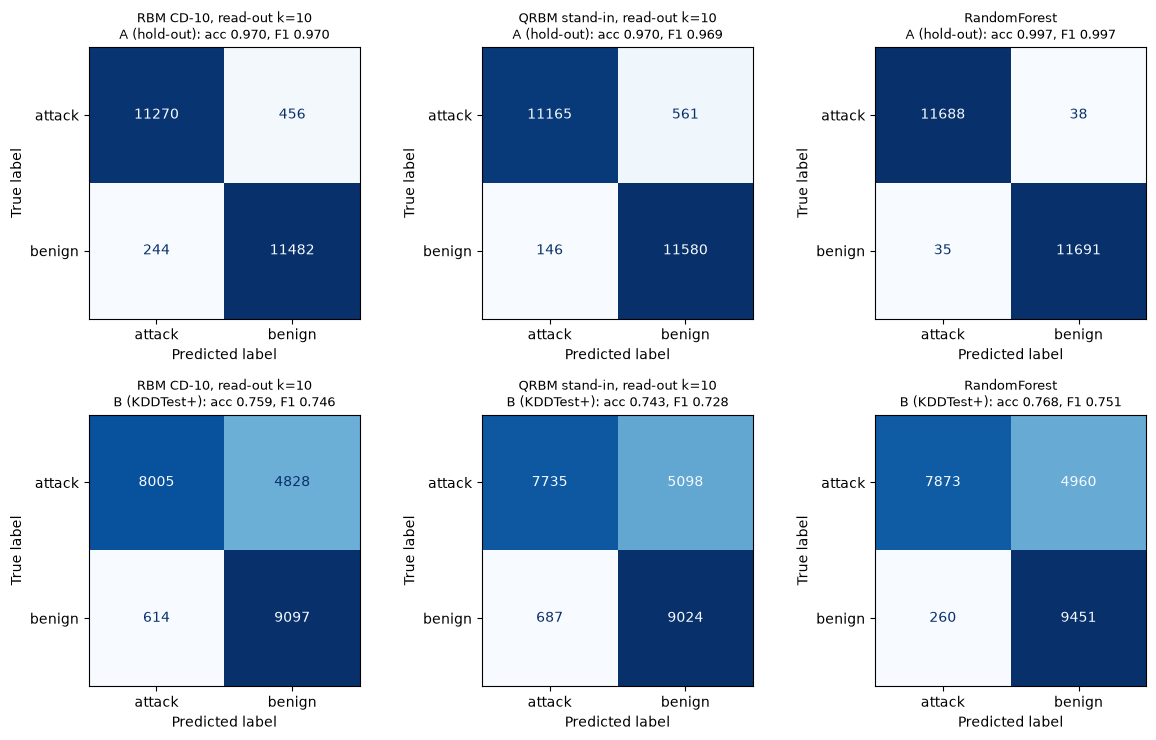

In [16]:
show = [("RBM CD-%d, read-out k=10" % K_TABLE1_TRAIN, lambda X: rbm_models[(K_TABLE1_TRAIN, 0)].classify(X, 10)),
        ("QRBM stand-in, read-out k=10", lambda X: qrbm_models[0].classify(X, 10)),
        ("RandomForest", None)]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for row, (proto, X, y) in enumerate([("A (hold-out)", X_test_A, y_test_A), ("B (KDDTest+)", X_test_B, y_test_B)]):
    for col, (name, fn) in enumerate(show):
        pred = baseline_preds["RandomForest (200 trees)"][row] if fn is None else fn(X)
        cm = confusion_matrix(y, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["attack", "benign"]).plot(ax=axes[row, col], colorbar=False, cmap="Blues")
        axes[row, col].set_title(f"{name}\n{proto}: acc {accuracy_score(y, pred):.3f}, F1 {f1_score(y, pred, pos_label=0):.3f}", fontsize=9)
plt.tight_layout(); plt.show()

## 13. Paper versus this notebook

One row per number the paper reports for NSL-KDD, under both test protocols. **reproduced** = within 0.02 (two accuracy
points / 0.02 F1) of the paper's value, **exceeded** / **not reached** otherwise with the gap, **cannot be checked** when
the quantity needs the QPU, **not run here** for settings `FAST_MODE` skipped. The qualitative claims (Fig. 5,
Supplementary Table 3, "QRBM comparable to RBM") are checked with the stated rule.

In [17]:
PAPER_TABLE1 = {1: (0.906, 0.901), 10: (0.935, 0.932), 100: (0.937, 0.934), 1000: (0.938, 0.935)}   # k_exploit -> (accuracy, F1)
PAPER_TABLE2 = dict(accuracy=0.937, f1=0.935, TP=0.951, FP=0.050, FN=0.073, TN=0.927)
TOL = 0.02
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "not run here"
    if abs(ours - paper) <= tol: return "reproduced"
    return f"{'exceeded' if ours > paper else 'not reached'} ({ours - paper:+.3f})"

rows = []
for proto in ["A (hold-out)", "B (KDDTest+)"]:
    for k, (p_acc, p_f1) in PAPER_TABLE1.items():
        r = table1_summary[(table1_summary.protocol == proto) & (table1_summary.k_exploit == str(k))]
        for met, p in [("accuracy", p_acc), ("f1", p_f1)]:
            o = float(r[met].iloc[0]) if len(r) else None
            rows.append(dict(source="Table 1", claim=f"RBM, exploitation k = {k}, {met}", protocol=proto, paper=p, notebook=None if o is None else round(o, 3), verdict=verdict(p, o)))
    r = table2_summary[table2_summary.protocol == proto]
    for met, p in PAPER_TABLE2.items():
        o = float(r[met].iloc[0]); rows.append(dict(source="Table 2", claim=f"QRBM, {met}", protocol=proto, paper=p, notebook=round(o, 3), verdict=verdict(p, o)))
    # Fig. 5: training k does not matter on NSL-KDD (rule: max - min of the mean accuracy over training k within 0.02)
    g = fig5_summary[fig5_summary.protocol == proto]; spread = float(g["accuracy"].max() - g["accuracy"].min())
    rows.append(dict(source="Fig. 5", claim="training k does not change NSL-KDD performance", protocol=proto, paper="flat", notebook=f"accuracy spread {spread:.3f} over k = {K_TRAIN_LIST}",
                     verdict="reproduced" if spread <= TOL else f"not reproduced (spread {spread:.3f})"))
    # QRBM comparable to RBM (rule: within 0.02 of the CD-10 model with the same read-out)
    rbm_acc = float(fig5_summary[(fig5_summary.protocol == proto) & (fig5_summary.k_train == K_TABLE1_TRAIN)]["accuracy"].iloc[0]); q_acc = float(r["accuracy"].iloc[0])
    rows.append(dict(source="Table 2 vs 1", claim="QRBM performance comparable to the classical RBM", protocol=proto, paper="0.937 vs 0.935 (k = 10)", notebook=f"{q_acc:.3f} vs {rbm_acc:.3f}",
                     verdict="reproduced" if abs(q_acc - rbm_acc) <= TOL else f"not reproduced ({q_acc - rbm_acc:+.3f})"))
    # Table 1 trend: accuracy rises with the exploitation k (paper: +0.032 from k = 1 to k = 1000)
    t1 = table1_summary[(table1_summary.protocol == proto) & (table1_summary.k_exploit != "exact")]
    gain = float(t1["accuracy"].iloc[-1] - t1["accuracy"].iloc[0])
    rows.append(dict(source="Table 1 (trend)", claim=f"accuracy rises with the exploitation k (k = 1 -> {K_EXPLOIT_LIST[-1]})", protocol=proto, paper="+0.032 (k = 1 -> 1000)", notebook=f"{gain:+.3f}",
                     verdict="reproduced (same direction)" if gain > 0.01 else ("tie (within 1 point)" if abs(gain) <= 0.01 else "not reproduced (opposite direction)")))
e = epochs_df.set_index("model")["updates_to_target"]
e_cd, e_q = e.get("CD-1"), e.get("QRBM stand-in")
rows.append(dict(source="Suppl. Table 3", claim=f"QRBM needs fewer epochs than the RBM to reach eta = {TARGET_ACC} (validation)", protocol="validation slice",
                 paper="fewer", notebook=f"CD-1: {e_cd} updates, QRBM stand-in: {e_q} updates",
                 verdict="not reached (never hit target)" if e_q is None else ("reproduced" if (e_cd is None or e_q < e_cd) else ("tie" if e_q == e_cd else "not reproduced (QRBM slower)"))))
for claim, p in [("negative phase, 1 core, k = 10: 0.070 s", 0.070), ("negative phase, 128 threads, k = 10: 0.035 s", 0.035), ("QPU access time, 10 samples: 0.016 s", 0.016),
                 ("speed-up 4x (1 core) / 2x (128 threads)", "4x / 2x")]:
    rows.append(dict(source="Table 3", claim=claim, protocol="-", paper=p,
                     notebook=f"this CPU: CD-10 {timing_df.seconds.iloc[1]*1000:.2f} ms (1 record) / {timing_df.seconds.iloc[5]*1000:.1f} ms (batch 100); stand-in {t_sa_only*1000:.1f} ms",
                     verdict="cannot be checked (no QPU; classical time is hardware- and implementation-specific)"))
rows.append(dict(source="Tables 1-3", claim="CSE-CIC-IDS2018 results (90 hidden units, 156 bits, 64x speed-up)", protocol="-", paper="see paper", notebook=None, verdict="not run here (dataset not used)"))
comparison = pd.DataFrame(rows); display(comparison)
print("verdict counts:", comparison["verdict"].str.replace(r" \(.*\)$", "", regex=True).value_counts().to_dict())

,source,claim,protocol,paper,notebook,verdict
0,Table 1,"RBM, exploitation k = 1, accuracy",A (hold-out),0.906,0.91,reproduced
1,Table 1,"RBM, exploitation k = 1, f1",A (hold-out),0.901,0.912,reproduced
2,Table 1,"RBM, exploitation k = 10, accuracy",A (hold-out),0.935,0.972,exceeded (+0.037)
3,Table 1,"RBM, exploitation k = 10, f1",A (hold-out),0.932,0.972,exceeded (+0.040)
4,Table 1,"RBM, exploitation k = 100, accuracy",A (hold-out),0.937,0.973,exceeded (+0.036)
5,Table 1,"RBM, exploitation k = 100, f1",A (hold-out),0.934,0.973,exceeded (+0.039)
6,Table 1,"RBM, exploitation k = 1000, accuracy",A (hold-out),0.938,0.973,exceeded (+0.035)
7,Table 1,"RBM, exploitation k = 1000, f1",A (hold-out),0.935,0.973,exceeded (+0.038)
8,Table 2,"QRBM, accuracy",A (hold-out),0.937,0.972,exceeded (+0.035)
9,Table 2,"QRBM, f1",A (hold-out),0.935,0.971,exceeded (+0.036)


verdict counts: {'not reached': 13, 'reproduced': 11, 'exceeded': 11, 'cannot be checked': 4, 'not run here': 1}


## Reading the paper critically

**Which test set?** The paper says the NSL-KDD test set has 22,543 records (that is `KDDTest+`) and, in the same
paragraph, that training and test are "roughly 80%:20%". `KDDTest+` contains 17 attack types never seen in training
and every published classifier trained on `KDDTrain+` lands at 75-85 % accuracy on it; our RBM, the stand-in QRBM, the
random forest and the SVM all do (protocol B). An RBM reaching 0.938 with symmetric TP/TN of 0.93-0.98 on `KDDTest+`
would be far outside the literature, whereas on a random 20 % hold-out of the balanced training file (protocol A) the
same RBM reaches it easily. The paper's NSL-KDD numbers are therefore most plausibly protocol-A numbers; this notebook
reports both so that the reader can decide, and the verdicts differ accordingly.

**"Epoch" cannot mean a pass over the data.** With the paper's own timing (0.070 s per negative phase at k = 10) and
2,000 epochs over 117,000 balanced records in batches, CD-1000 training would take weeks; the quantum budget
(2,000 QPU calls x 0.016 s = 32 s) only makes sense if an epoch is one update. Batch size, learning rate and
initialisation live in a supplementary table that is not in the article, so the training-k and exploitation-k numbers
of Table 1 (and the "epochs to target accuracy" of Supplementary Table 3) depend on choices a reader has to make.

**The exploitation-time argument does not apply to an RBM used as a classifier.** Table 1 and Table 3 argue that
querying the model needs many Gibbs steps (hence the QPU helps). But with the feature bits clamped, the hidden units
can be summed out analytically and the posterior over the 8 label-bit patterns is exact in one free-energy evaluation
per pattern (Section 4, `classify_exact`; Section 10 shows it agrees with the sampler). No sampling is needed at all
during exploitation, on any hardware; the only place where sampling is unavoidable is the negative phase of training.

**What the speed-up measures.** Table 3 compares QPU *access* time (programming excluded, network latency excluded,
embedding computed beforehand) with a CPU implementation whose negative phase for a 116-unit model and k = 10 takes
70 ms. The same computation in plain numpy on a laptop core takes well under a millisecond here (Section 11): the
classical column of Table 3 is implementation-bound, so the quoted 4x and 64x factors say little about the algorithms.
What the paper does establish, and what this notebook confirms with the stand-in, is the qualitative point that an RBM
can be trained with only 10 model samples per update; whether a QPU delivers those 10 samples faster than a CPU
delivers 10 Gibbs chains is a question about hardware that only the hardware can answer.

**Ten samples is a noisy gradient.** The negative phase from 10 joint samples has a variance comparable to CD-1 with a
batch of 10; it works because the learning rate is small and the updates are many. Section 9 shows the stand-in QRBM
and the CD-1 RBM reach the same accuracy in a similar number of updates; the sign of the "fewer epochs" claim of
Supplementary Table 3 is within run-to-run noise here.

**Training k really does not matter on NSL-KDD** (Fig. 5), and the model saturates early: this task is easy once the
features are binarised, as the baselines on the same bits show (Section 6). Any comparison of samplers on it is a
comparison on a problem where the sampler's quality is irrelevant; the paper's own Fig. 5 says as much for the training
phase.

## Exercises

1. **Which protocol did the paper use?** Train the random forest of Section 6 on the *unbalanced* `KDDTrain+` and
   evaluate on `KDDTest+`. Does any model on these bits exceed 0.85 under protocol B? What does that say about the
   paper's Table 1?
2. **Bits per feature.** Set `N_BINS = 4` (two bits per real-valued feature, 73 + 3 bits) and `N_BINS = 16`. How do the
   RBM accuracy, the negative-phase time and the stand-in time scale with the number of visible units (the paper's
   Fig. 2-4 trend)?
3. **Effective temperature.** The annealer samples at an unknown $T_{eff}$ that the paper corrects with $\alpha$. Set
   `SA_BETA_RANGE = (0.1, 0.5)` (i.e. $T_{eff} = 2$ with $\alpha = 1$) and retrain the stand-in QRBM. How much accuracy
   is lost, and does setting `ALPHA = 2.0` recover it?
4. **How many samples does the negative phase need?** Train the stand-in QRBM with `QPU_SAMPLES = 1, 3, 10, 100` and
   plot the learning curves of Section 9. Where does the curve stop improving, and how does the sampler time grow?
5. **Exact exploitation.** Replace every `classify(X, k)` in Section 7 by `classify_exact(X)` and re-run Table 1. Is
   there any exploitation k for which the Gibbs read-out beats the exact posterior? Explain why the answer rules out an
   exploitation-phase speed-up for RBM classifiers.